<a href="https://colab.research.google.com/github/odamasceno/Calculo-Numerico/blob/main/atividade_19_10_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lista de Exercícios — Sistemas lineares em cálculo numérico

### Rafael Damasceno Marques dos Santos - RA: 187561


## Questão 5 — Implementação do método de Gauss–Seidel


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def gauss_seidel(x0, tol=1e-5, max_iter=1000):
    x, y, z = x0
    historico = [(x, y, z)]
    erros = []

    for k in range(1, max_iter + 1):
        x_ant, y_ant, z_ant = x, y, z

        # Gauss-Seidel
        x = (6 + y_ant - 2 * z_ant) / 10      # usa y^(k-1 e z^(k-1)
        y = (22 + x + z_ant) / 11             # usa x^(k  e z^(k-1)
        z = (-10 - 2 * x + y) / 10            #usa x^(k) e y^(k)

        erro = max(abs(x - x_ant), abs(y - y_ant), abs(z - z_ant))   # norma do máximo
        historico.append((x, y, z))
        erros.append(erro)

        if erro < tol:
            break

    return historico, erros

In [4]:
x0 = (0.0, 0.0, 0.0)   # aproximação inicial x^(0)
tol = 1e-5

historico, erros = gauss_seidel(x0, tol=tol)

n_iter = len(erros)
x_sol, y_sol, z_sol = historico[-1]

print(f"Número de iterações realizadas: {n_iter}")
print("Solução aproximada obtida:")
print(f"  x ≈ {x_sol:.8f}")
print(f"  y ≈ {y_sol:.8f}")
print(f"  z ≈ {z_sol:.8f}")
print(f"Erro final = {erros[-1]:.3e}")

Número de iterações realizadas: 6
Solução aproximada obtida:
  x ≈ 1.00000003
  y ≈ 1.99999998
  z ≈ -1.00000001
Erro final = 1.263e-06


## Questão 6 — Tabela com os resultados das iterações

In [5]:
ks = list(range(len(historico)))
xs = [h[0] for h in historico]
ys = [h[1] for h in historico]
zs = [h[2] for h in historico]
erros_col = [np.nan] + erros   # k = 0 não possui erro entre iterações

tabela = pd.DataFrame({
    "k": ks,
    "x(k)": xs,
    "y(k)": ys,
    "z(k)": zs,
    "||x(k) - x(k-1)||∞": erros_col,
})

(tabela.style
    .format({"x(k)": "{:.8f}", "y(k)": "{:.8f}", "z(k)": "{:.8f}",
             "||x(k) - x(k-1)||∞": "{:.3e}"}, na_rep="—")
    .hide(axis="index"))

k,x(k),y(k),z(k),||x(k) - x(k-1)||∞
0,0.00000000,0.00000000,0.00000000,—
1,0.60000000,2.05454545,-0.91454545,2.055e+00
2,0.98836364,2.00671074,-0.99700165,3.884e-01
3,1.00007140,2.00027907,-0.99998637,1.171e-02
4,1.00002518,2.00000353,-1.00000468,2.755e-04
5,1.00000129,1.99999969,-1.00000029,2.389e-05
6,1.00000003,1.99999998,-1.00000001,1.263e-06


## Questão 7 — Gráficos

### (a) $x^{(k)}$, $y^{(k)}$ e $z^{(k)}$ em função de $k$ (mesmo gráfico)

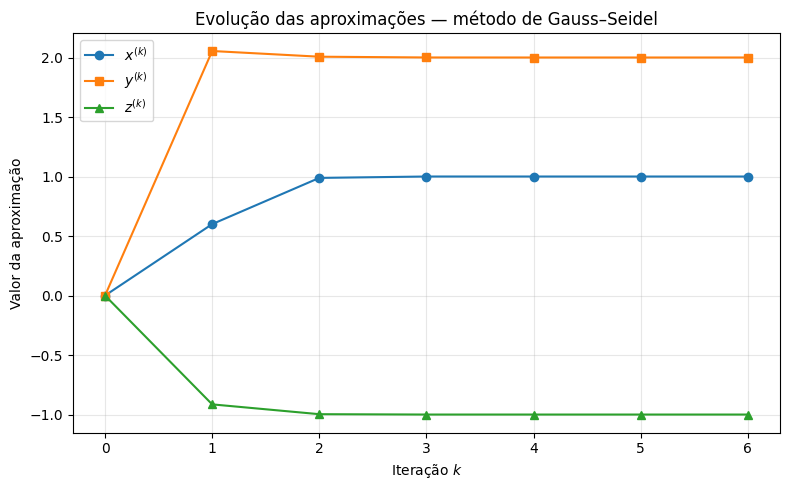

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(ks, xs, "o-", label="$x^{(k)}$")
plt.plot(ks, ys, "s-", label="$y^{(k)}$")
plt.plot(ks, zs, "^-", label="$z^{(k)}$")

plt.title("Evolução das aproximações — método de Gauss–Seidel")
plt.xlabel("Iteração $k$")
plt.ylabel("Valor da aproximação")
plt.xticks(ks)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### (b) Erro entre iterações em escala logarítmica

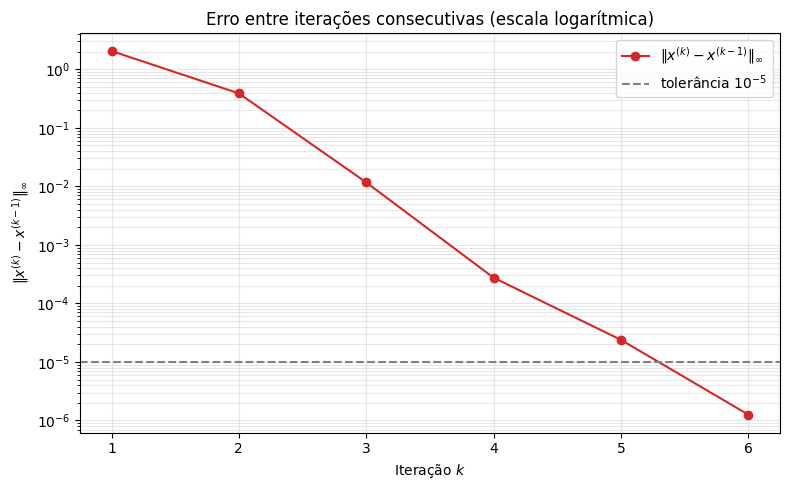

In [7]:
ks_erro = list(range(1, len(erros) + 1))   # o erro existe a partir de k = 1

plt.figure(figsize=(8, 5))
plt.semilogy(ks_erro, erros, "o-", color="tab:red",
             label=r"$\|x^{(k)} - x^{(k-1)}\|_\infty$")
plt.axhline(tol, color="gray", linestyle="--", label=r"tolerância $10^{-5}$")

plt.title("Erro entre iterações consecutivas (escala logarítmica)")
plt.xlabel("Iteração $k$")
plt.ylabel(r"$\|x^{(k)} - x^{(k-1)}\|_\infty$")
plt.xticks(ks_erro)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()